# Анализ данных эксперимента с email рассылками 

## Изучаю структуру и качество данных, описываю клиентскую базу и готовлю данные к эксперименту 

In [4]:
from pathlib import Path

import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

data_path = ROOT / "data" / "hillstrom.csv"
df = pd.read_csv(data_path)

print(f"Строк: {df.shape[0]:,}")
print(f"Столбцов: {df.shape[1]}")

display(df.head())
df.info()

Строк: 64,000
Столбцов: 12


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), str(4)
memory usage: 5.9 MB


### Описание данных

В датасете 64 000 клиентов. Их случайно разделили на три группы: одним отправили письмо с мужским ассортиментом, другим — с женским, третьим ничего не отправляли. Затем две недели наблюдали за результатами.

Каждая строка — один клиент:

- `recency` — сколько месяцев прошло с последней покупки до эксперимента.
- `history_segment` — группа клиента по сумме прошлогодних покупок.
- `history` — сколько долларов клиент потратил за предыдущий год.
- `mens` — покупал ли мужской ассортимент за предыдущий год: 1 — да, 0 — нет.
- `womens` — покупал ли женский ассортимент за предыдущий год: 1 — да, 0 — нет.
- `zip_code` — тип места проживания: город, пригород или сельская местность.
- `newbie` — стал ли новым клиентом за последние 12 месяцев: 1 — да, 0 — нет.
- `channel` — как покупал раньше: по телефону, через сайт или через несколько каналов.
- `segment` — какое письмо получил: с мужским ассортиментом, с женским или без письма.
- `visit` — посетил ли сайт за две недели наблюдения.
- `conversion` — совершил ли покупку за эти две недели.
- `spend` — сколько долларов потратил за эти две недели.



### Проверка качества данных

In [ ]:
# пропуски и типы данных
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(2),
    "unique_count": df.nunique(),
})

display(quality)

,dtype,missing_count,missing_pct,unique_count
recency,int64,0,0.0,12
history_segment,str,0,0.0,7
history,float64,0,0.0,34833
mens,int64,0,0.0,2
womens,int64,0,0.0,2
zip_code,str,0,0.0,3
newbie,int64,0,0.0,2
channel,str,0,0.0,3
segment,str,0,0.0,3
visit,int64,0,0.0,2


In [6]:
# повторы 
duplicate_count = df.duplicated().sum()

print(f"Повторяющихся строк сверх первого вхождения: {duplicate_count}")
print(f"Доля: {duplicate_count / len(df):.2%}")


Повторяющихся строк сверх первого вхождения: 6562
Доля: 10.25%


In [ ]:
# значения категориальных признаков 
categorical_columns = [
    "history_segment",
    "zip_code",
    "channel",
    "segment",
]

for column in categorical_columns:
    print(f"\n{column}")
    display(df[column].value_counts(dropna=False).to_frame("count"))


history_segment


,count
history_segment,
1) $0 - $100,22970
2) $100 - $200,14254
3) $200 - $350,12289
4) $350 - $500,6409
5) $500 - $750,4911
"6) $750 - $1,000",1859
"7) $1,000 +",1308



zip_code


,count
zip_code,
Surburban,28776
Urban,25661
Rural,9563



channel


,count
channel,
Web,28217
Phone,28021
Multichannel,7762



segment


,count
segment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


In [ ]:
# проверка на корректность данных
binary_columns = ["mens", "womens", "newbie", "visit", "conversion"]

checks = {
    f"{column}: значения вне 0 и 1":
        (~df[column].isin([0, 1]) & df[column].notna()).sum()
    for column in binary_columns
}

checks.update({
    "recency: значения вне диапазона 1–12":
        (df["recency"].notna() & ~df["recency"].between(1, 12)).sum(),

    "history: отрицательные значения":
        (df["history"] < 0).sum(),

    "spend: отрицательные значения":
        (df["spend"] < 0).sum(),
})

display(pd.Series(checks, name="count").to_frame())

,count
mens: значения вне 0 и 1,0
womens: значения вне 0 и 1,0
newbie: значения вне 0 и 1,0
visit: значения вне 0 и 1,0
conversion: значения вне 0 и 1,0
recency: значения вне диапазона 1–12,0
history: отрицательные значения,0
spend: отрицательные значения,0


In [ ]:
# доп проверка
consistency_checks = {
    "Есть расходы, но conversion = 0":
        ((df["spend"] > 0) & (df["conversion"] == 0)).sum(),

    "conversion = 1, но расходы равны 0":
        ((df["conversion"] == 1) & (df["spend"] == 0)).sum(),

    "Есть покупка, но visit = 0":
        ((df["conversion"] == 1) & (df["visit"] == 0)).sum(),
}

display(pd.Series(consistency_checks, name="count").to_frame())

,count
"Есть расходы, но conversion = 0",0
"conversion = 1, но расходы равны 0",0
"Есть покупка, но visit = 0",0


Противоречий между visit, conversion и spend в выполненных проверках не обнаружено.

### Клиентская база до эксперимента

Изучу давность последней покупки и расходы за предыдущий год.
Это поможет понять, насколько различаются клиенты по покупательской
активности.

In [14]:
display(
    df[["recency", "history"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .round(2)
)

,recency,history
count,64000.00,64000.00
mean,5.76,242.09
std,3.51,256.16
min,1.00,29.99
25%,2.00,64.66
50%,6.00,158.11
75%,9.00,325.66
90%,10.00,561.19
95%,11.00,747.26
99%,12.00,1218.66


Matplotlib is building the font cache; this may take a moment.


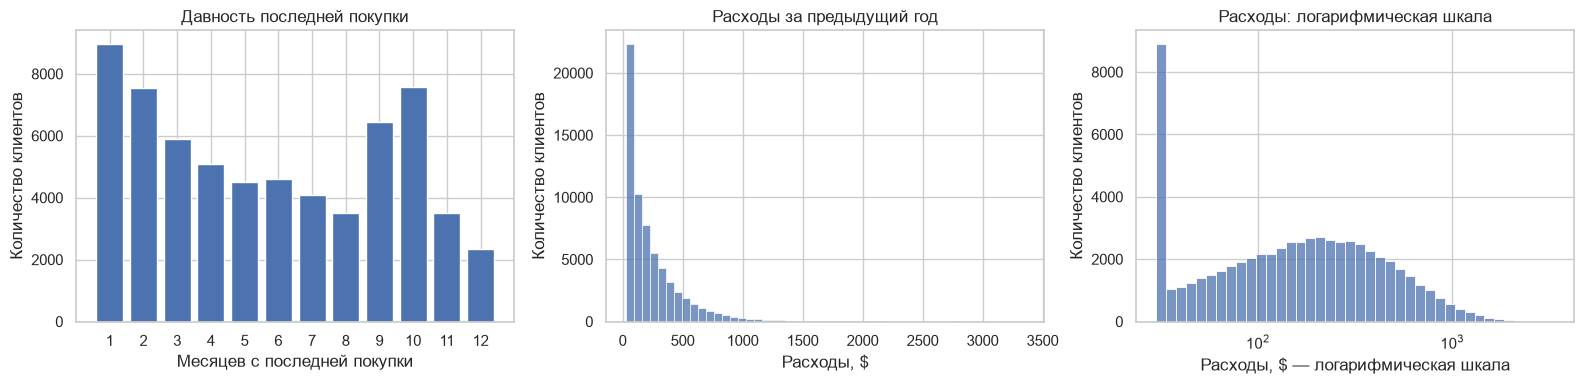

In [ ]:
# распределение 

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Давность последней покупки
recency_counts = (
    df["recency"]
    .value_counts()
    .sort_index()
)

axes[0].bar(recency_counts.index, recency_counts.values)
axes[0].set(
    title="Давность последней покупки",
    xlabel="Месяцев с последней покупки",
    ylabel="Количество клиентов",
)
axes[0].set_xticks(range(1, 13))

# Расходы в исходном масштабе
sns.histplot(data=df, x="history", bins=50, ax=axes[1])
axes[1].set(
    title="Расходы за предыдущий год",
    xlabel="Расходы, $",
    ylabel="Количество клиентов",
)

# Те же расходы в логарифмическом масштабе
sns.histplot(
    data=df.loc[df["history"] > 0],
    x="history",
    bins=40,
    log_scale=True,
    ax=axes[2],
)
axes[2].set(
    title="Расходы: логарифмическая шкала",
    xlabel="Расходы, $ — логарифмическая шкала",
    ylabel="Количество клиентов",
)

plt.tight_layout()
plt.show()

### Давность покупок и исторические расходы

Чаще всего встречаются клиенты, совершившие последнюю покупку один месяц назад. Также заметны повышенные количества клиентов с давностью покупки 9–10 месяцев. Причину этих пиков по имеющимся данным установить нельзя.

Распределение расходов за предыдущий год имеет выраженную правостороннюю асимметрию: небольшие суммы встречаются часто, крупные — значительно реже. Логарифмическая шкала позволяет подробнее рассмотреть распределение.

In [ ]:
# На третьем графике также заметно скопление около минимальных расходов. Проверим, связано ли оно с часто повторяющимся значением
display(
    df["history"]
    .value_counts()
    .head(10)
    .rename_axis("history")
    .to_frame("clients")
)

,clients
history,
29.99,7947
81.20,9
53.79,9
35.40,8
72.97,8
41.89,8
47.03,8
33.18,8
44.14,8


Пик объясняется частым значением 29,99 $: оно встречается у 7 947 клиентов — примерно 12,4% выборки. Следующие по частоте суммы встречаются всего по 8–9 раз.

Это также может объяснять часть полностью совпадающих строк: у многих клиентов одинаковые расходы, а остальные признаки принимают ограниченное число значений.


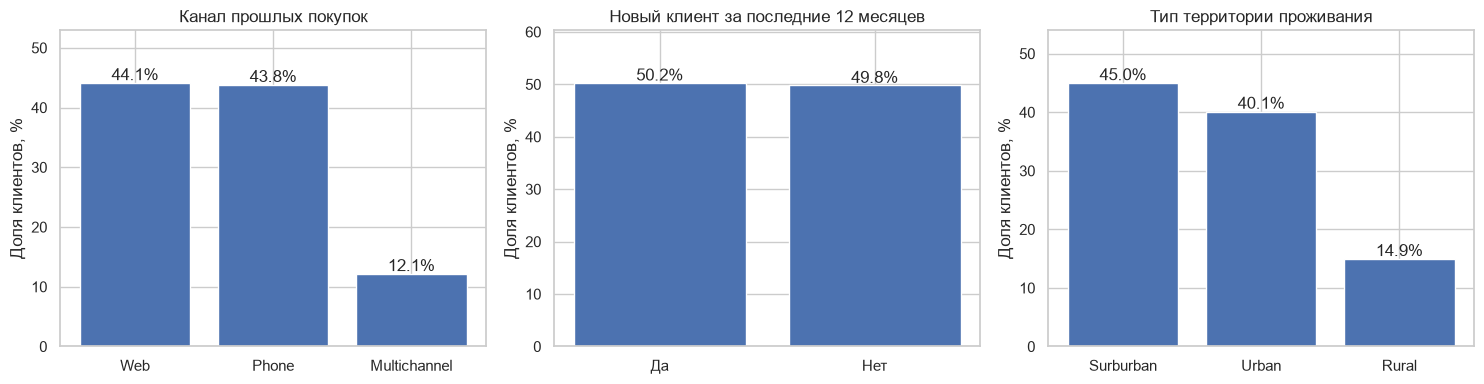

In [18]:
columns = {
    "channel": "Канал прошлых покупок",
    "newbie": "Новый клиент за последние 12 месяцев",
    "zip_code": "Тип территории проживания",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (column, title) in zip(axes, columns.items()):
    shares = df[column].value_counts(normalize=True).mul(100)

    if column == "newbie":
        shares = shares.rename(index={0: "Нет", 1: "Да"})

    ax.bar(shares.index.astype(str), shares.values)
    ax.set_title(title)
    ax.set_ylabel("Доля клиентов, %")
    ax.set_ylim(0, shares.max() * 1.2)

    for i, value in enumerate(shares.values):
        ax.text(i, value + 0.5, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Клиенты почти одинаково часто покупали через сайт (44,1%) и по телефону (43,8%). Несколько каналов использовали 12,1%.

Новые клиенты составляют 50,2% выборки, остальные — 49,8%.

Большинство клиентов живут в пригороде (45,0%) или городе (40,1%). На сельскую местность приходится 14,9%.

Эти распределения описывают состав выборки. Эффективность рассылок для разных категорий клиентов пока не оценивалась.

### Общие показатели за период наблюдения

Рассмотрю посещения, покупки и расходы по всей выборке.
Сравнение экспериментальных групп будет выполнено отдельно.

In [19]:
summary = pd.Series({
    "Количество клиентов": len(df),
    "Посетили сайт": df["visit"].sum(),
    "Доля посетивших сайт, %": df["visit"].mean() * 100,
    "Совершили покупку": df["conversion"].sum(),
    "Конверсия в покупку, %": df["conversion"].mean() * 100,
    "Доля с нулевыми расходами, %": df["spend"].eq(0).mean() * 100,
    "Средние расходы на клиента, $": df["spend"].mean(),
    "Медианные расходы на клиента, $": df["spend"].median(),
})

display(summary.round(2).to_frame("value"))

,value
Количество клиентов,64000.00
Посетили сайт,9394.00
"Доля посетивших сайт, %",14.68
Совершили покупку,578.00
"Конверсия в покупку, %",0.90
"Доля с нулевыми расходами, %",99.10
"Средние расходы на клиента, $",1.05
"Медианные расходы на клиента, $",0.00


,spend_among_buyers
count,578.00
mean,116.36
std,107.87
min,29.99
50%,80.80
90%,256.49
95%,362.20
99%,499.00
max,499.00


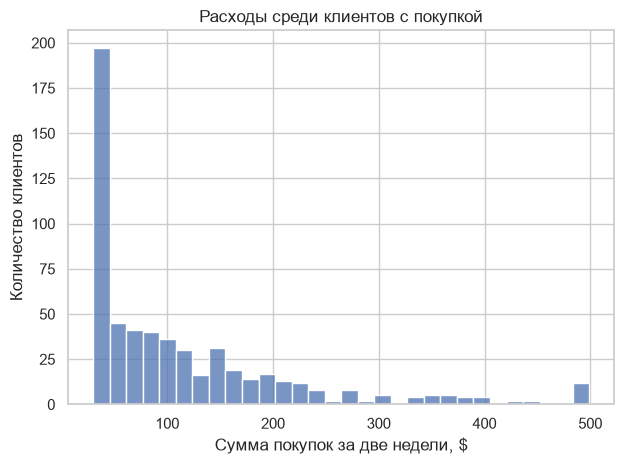

In [ ]:
buyers = df.loc[df["conversion"] == 1]

display(
    buyers["spend"]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(2)
    .to_frame("spend_among_buyers")
)

sns.histplot(data=buyers, x="spend", bins=30)
plt.title("Расходы среди клиентов с покупкой")
plt.xlabel("Сумма покупок за две недели, $")
plt.ylabel("Количество клиентов")
plt.tight_layout()
plt.show()

### Показатели за две недели наблюдения

Из 64 000 клиентов сайт посетили 9 394 человека (14,68%), покупку совершили 578 человек (0,90%).

У 99,10% клиентов расходы равны нулю. Средняя сумма покупок на клиента составляет 1,05 $, медианная — 0 $.

Среди покупателей средняя сумма расходов составляет 116,36 $, медианная — 80,80 $. Распределение скошено вправо: большинство покупателей тратят относительно небольшие суммы, а отдельные крупные значения повышают среднее.

Из-за редких покупок и неоднородных расходов при оценке эффекта потребуется учитывать неопределённость результатов. В основной метрике сохраняются все клиенты, включая непокупателей.


### Итоги EDA

Клиенты различаются по давности покупок и историческим расходам. Распределение расходов имеет длинный правый хвост, а значение 29,99 $ встречается особенно часто.

Обнаружено 6 562 полностью совпадающие строки. Идентификатора клиента нет, поэтому установить природу совпадений невозможно. Строки сохранены.

В выполненных проверках противоречий между посещением сайта, фактом покупки и расходами не обнаружено.

За две недели покупку совершили 578 клиентов — около 0,90% выборки. У остальных расходы равны нулю. Средние расходы на клиента составляют 1,05 $, медианные — 0 $.

При оценке эффекта рассылок необходимо учитывать редкие покупки и неоднородность расходов. Основная метрика будет рассчитываться по всем клиентам, включая непокупателей.

Следующий этап — проверка размеров экспериментальных групп и их сопоставимости по характеристикам до рассылки.